# Final Six-Owner Model Comparison + 5-Fold Cross-Validation

This notebook compares the **six student-owned model results** and combines the 5-fold cross-validation summaries.

| Member | Student | IT Number | Model |
|---:|---|---|---|
| 1 | Weerakkody W.W.M.B | IT25101776 | Custom CNN |
| 2 | Hettiarachchi H.A.A.S | IT25104064 | EfficientNetB0 |
| 3 | Thennakoon T.M.A.N | IT25100854 | MLP |
| 4 | Senanayake S.M.K.D | IT25100233 | SVM |
| 5 | Malintha K.K.I | IT25102346 | MobileNetV3Small |
| 6 | Somarathne R.N.N | IT25100295 | DenseNet121 |

**Final best model from the completed hold-out validation comparison:** MobileNetV3Small (Malintha K.K.I), selected using the predefined **Validation Macro F1** rule. The notebook still calculates the ranking from the uploaded real result CSV files rather than hard-coding scores.


## Selection Rule

The primary model/variant selection metric is **Validation Macro F1** from the stratified hold-out Validation set.

The additional **5-fold stratified cross-validation Mean Macro F1** is used as robustness/generalization evidence. The Official Test set remains separate and is used only for final reporting.

Based on the completed project results, **MobileNetV3Small is the final selected best model** under the predefined Validation Macro F1 rule.


## 1. Upload the Six Final Result CSV Files

In [1]:
from google.colab import files
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

uploaded = files.upload()

csv_files = {
    name: content
    for name, content in uploaded.items()
    if name.lower().endswith(".csv")
}

print("CSV files uploaded:", len(csv_files))
for name in csv_files:
    print("-", name)

Saving efficientnetb0_final_result.csv to efficientnetb0_final_result.csv
Saving it25100233_svm_final_result.csv to it25100233_svm_final_result.csv
Saving it25100295_densenet121_final_result.csv to it25100295_densenet121_final_result.csv
Saving it25100854_mlp_final_result.csv to it25100854_mlp_final_result.csv
Saving it25101776_custom_cnn_final_result.csv to it25101776_custom_cnn_final_result.csv
Saving it25102346_mobilenetv3small_final_result.csv to it25102346_mobilenetv3small_final_result.csv
CSV files uploaded: 6
- efficientnetb0_final_result.csv
- it25100233_svm_final_result.csv
- it25100295_densenet121_final_result.csv
- it25100854_mlp_final_result.csv
- it25101776_custom_cnn_final_result.csv
- it25102346_mobilenetv3small_final_result.csv


## 2. Normalize Result Columns

In [2]:
def normalize_result(filename, content):
    df = pd.read_csv(io.BytesIO(content))

    if len(df) == 0:
        raise ValueError(f"{filename} is empty.")

    row = df.iloc[0].to_dict()

    def first_value(names):
        for name in names:
            if name in row and pd.notna(row[name]):
                return row[name]
        return None

    return {
        "Source File": filename,
        "Student": first_value([
            "Student",
            "Model Owner",
            "Owner",
        ]),
        "IT Number": first_value([
            "IT Number",
            "Owner IT Number",
        ]),
        "Model": first_value(["Model"]),
        "Selected Variant": first_value(["Selected Variant"]),
        "Selected Variant Name": first_value([
            "Selected Variant Name"
        ]),
        "Validation F1": first_value(["Validation F1"]),
        "Test Accuracy": first_value(["Test Accuracy"]),
        "Test Precision": first_value([
            "Test Precision",
            "Test Precision Macro"
        ]),
        "Test Recall": first_value([
            "Test Recall",
            "Test Recall Macro"
        ]),
        "Test F1": first_value([
            "Test F1",
            "Test F1 Macro"
        ]),
    }


results = pd.DataFrame([
    normalize_result(name, content)
    for name, content in csv_files.items()
])

numeric_columns = [
    "Validation F1",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
]

for column in numeric_columns:
    results[column] = pd.to_numeric(
        results[column],
        errors="coerce"
    )

results["Owner + Model"] = (
    results["Student"].fillna("Unknown Owner")
    + " — "
    + results["Model"].fillna("Unknown Model")
)

display(results)

,Source File,Student,IT Number,Model,Selected Variant,Selected Variant Name,Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1,Owner + Model
0,efficientnetb0_final_result.csv,Hettiarachchi H.A.A.S,IT25104064,EfficientNetB0,A,Strong Transfer Learning,0.853173,0.700508,0.715766,0.711718,0.690475,Hettiarachchi H.A.A.S — EfficientNetB0
1,it25100233_svm_final_result.csv,Senanayake S.M.K.D,IT25100233,SVM,B,Standard Linear SVM,0.752701,0.675127,0.710640,0.675853,0.646468,Senanayake S.M.K.D — SVM
2,it25100295_densenet121_final_result.csv,Somarathne R.N.N,IT25100295,DenseNet121,A,Strong Transfer Learning,0.883468,0.697970,0.720980,0.695581,0.676117,Somarathne R.N.N — DenseNet121
3,it25100854_mlp_final_result.csv,Thennakoon T.M.A.N,IT25100854,MLP,B,Regularized Deep MLP,0.844306,0.642132,0.698127,0.642241,0.611649,Thennakoon T.M.A.N — MLP
4,it25101776_custom_cnn_final_result.csv,Weerakkody W.W.M.B,IT25101776,Custom CNN,B,Deeper Regularized CNN,0.815102,0.474619,0.592580,0.473476,0.461268,Weerakkody W.W.M.B — Custom CNN
5,it25102346_mobilenetv3small_final_result.csv,Malintha K.K.I,IT25102346,MobileNetV3Small,B,Deep Regularized Fine-Tuning,0.903505,0.705584,0.734970,0.703659,0.677923,Malintha K.K.I — MobileNetV3Small


## 3. Rank by Validation Macro F1

In [3]:
ranking = (
    results
    .sort_values(
        "Validation F1",
        ascending=False
    )
    .reset_index(drop=True)
)

ranking.insert(
    0,
    "Rank",
    np.arange(1, len(ranking) + 1)
)

display(
    ranking[
        [
            "Rank",
            "Student",
            "IT Number",
            "Model",
            "Selected Variant",
            "Selected Variant Name",
            "Validation F1",
            "Test Accuracy",
            "Test Precision",
            "Test Recall",
            "Test F1",
        ]
    ]
)

,Rank,Student,IT Number,Model,Selected Variant,Selected Variant Name,Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,1,Malintha K.K.I,IT25102346,MobileNetV3Small,B,Deep Regularized Fine-Tuning,0.903505,0.705584,0.734970,0.703659,0.677923
1,2,Somarathne R.N.N,IT25100295,DenseNet121,A,Strong Transfer Learning,0.883468,0.697970,0.720980,0.695581,0.676117
2,3,Hettiarachchi H.A.A.S,IT25104064,EfficientNetB0,A,Strong Transfer Learning,0.853173,0.700508,0.715766,0.711718,0.690475
3,4,Thennakoon T.M.A.N,IT25100854,MLP,B,Regularized Deep MLP,0.844306,0.642132,0.698127,0.642241,0.611649
4,5,Weerakkody W.W.M.B,IT25101776,Custom CNN,B,Deeper Regularized CNN,0.815102,0.474619,0.592580,0.473476,0.461268
5,6,Senanayake S.M.K.D,IT25100233,SVM,B,Standard Linear SVM,0.752701,0.675127,0.710640,0.675853,0.646468


## 4. Validation Macro F1 Chart

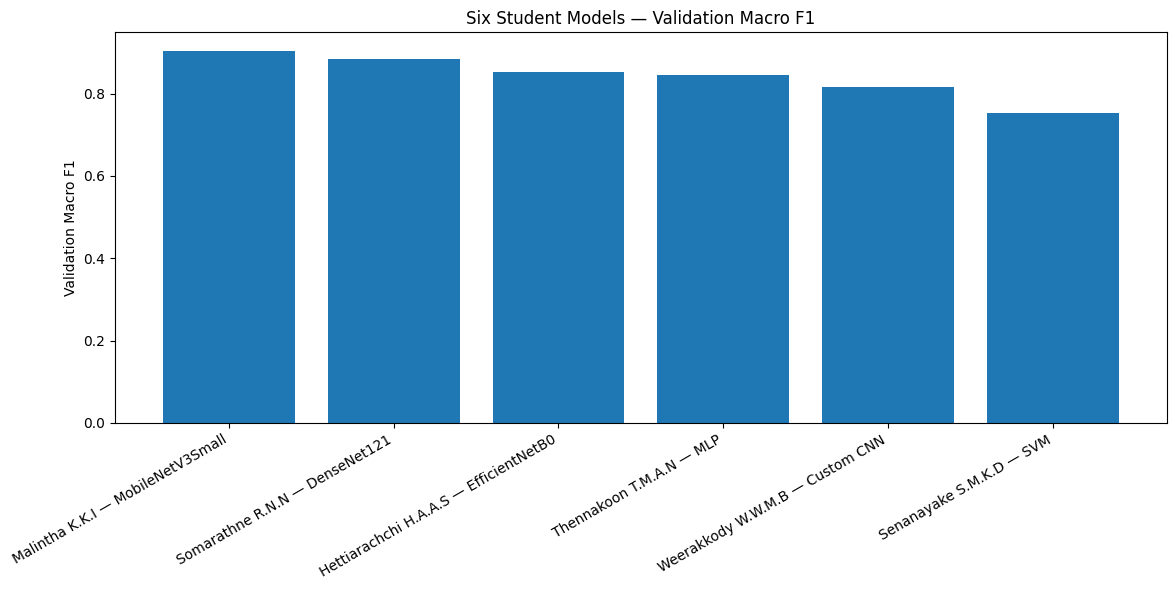

In [4]:
plt.figure(figsize=(12, 6))
plt.bar(
    ranking["Owner + Model"],
    ranking["Validation F1"]
)
plt.title("Six Student Models — Validation Macro F1")
plt.ylabel("Validation Macro F1")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 5. Official Test Macro F1 Chart

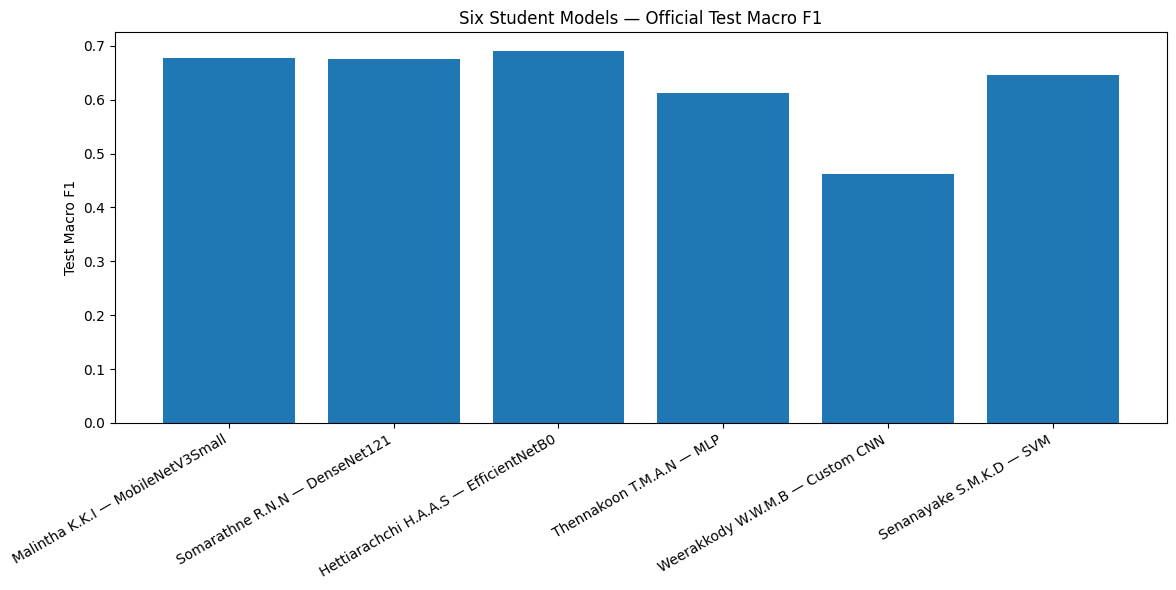

In [5]:
plt.figure(figsize=(12, 6))
plt.bar(
    ranking["Owner + Model"],
    ranking["Test F1"]
)
plt.title("Six Student Models — Official Test Macro F1")
plt.ylabel("Test Macro F1")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Validation-to-Test Gap

In [6]:
gap = ranking[
    [
        "Owner + Model",
        "Validation F1",
        "Test F1"
    ]
].copy()

gap["Validation-Test F1 Gap"] = (
    gap["Validation F1"]
    - gap["Test F1"]
)

display(gap)

,Owner + Model,Validation F1,Test F1,Validation-Test F1 Gap
0,Malintha K.K.I — MobileNetV3Small,0.903505,0.677923,0.225582
1,Somarathne R.N.N — DenseNet121,0.883468,0.676117,0.207351
2,Hettiarachchi H.A.A.S — EfficientNetB0,0.853173,0.690475,0.162698
3,Thennakoon T.M.A.N — MLP,0.844306,0.611649,0.232656
4,Weerakkody W.W.M.B — Custom CNN,0.815102,0.461268,0.353835
5,Senanayake S.M.K.D — SVM,0.752701,0.646468,0.106233


## 7. Upload and Compare the Six 5-Fold CV Summary Files

Run **Topic 18** in every individual model notebook first, then upload the six owner-specific `*_5fold_cv_summary.csv` files below.

This produces the report-ready Fold 1–5 table and the **5-Fold Cross-Validation — Mean Macro F1 Comparison** chart.


Upload the SIX *_5fold_cv_summary.csv files now.


Saving it25100233_svm_5fold_cv_summary.csv to it25100233_svm_5fold_cv_summary.csv
Saving it25100295_densenet121_5fold_cv_summary.csv to it25100295_densenet121_5fold_cv_summary.csv
Saving it25100854_mlp_5fold_cv_summary.csv to it25100854_mlp_5fold_cv_summary.csv
Saving it25101776_custom_cnn_5fold_cv_summary.csv to it25101776_custom_cnn_5fold_cv_summary.csv
Saving it25102346_mobilenetv3small_5fold_cv_summary.csv to it25102346_mobilenetv3small_5fold_cv_summary.csv
Saving it25104064_efficientnetb0_5fold_cv_summary.csv to it25104064_efficientnetb0_5fold_cv_summary.csv
FINAL 5-FOLD CROSS-VALIDATION COMPARISON


,CV Rank,Owner,IT Number,Model,Selected Variant,Selected Variant Name,Fold 1 F1,Fold 2 F1,Fold 3 F1,Fold 4 F1,Fold 5 F1,Mean CV F1,Std CV F1
0,1,Somarathne R.N.N,IT25100295,DenseNet121,A,Strong Transfer Learning,0.8767,0.9097,0.9260,0.9244,0.9092,0.9092,0.0198
1,2,Hettiarachchi H.A.A.S,IT25104064,EfficientNetB0,A,Strong Transfer Learning,0.8837,0.8707,0.9058,0.9276,0.8868,0.8949,0.0222
2,3,Malintha K.K.I,IT25102346,MobileNetV3Small,B,Deep Regularized Fine-Tuning,0.8851,0.8853,0.9009,0.8947,0.9007,0.8933,0.0078
3,4,Thennakoon T.M.A.N,IT25100854,MLP,B,Regularized Deep MLP,0.8404,0.8417,0.8713,0.8358,0.8480,0.8474,0.0140
4,5,Weerakkody W.W.M.B,IT25101776,Custom CNN,B,Deeper Regularized CNN,0.8203,0.8587,0.8454,0.7831,0.6968,0.8009,0.0649
5,6,Senanayake S.M.K.D,IT25100233,SVM,B,Standard Linear SVM,0.7624,0.8178,0.8130,0.7945,0.7536,0.7883,0.0291


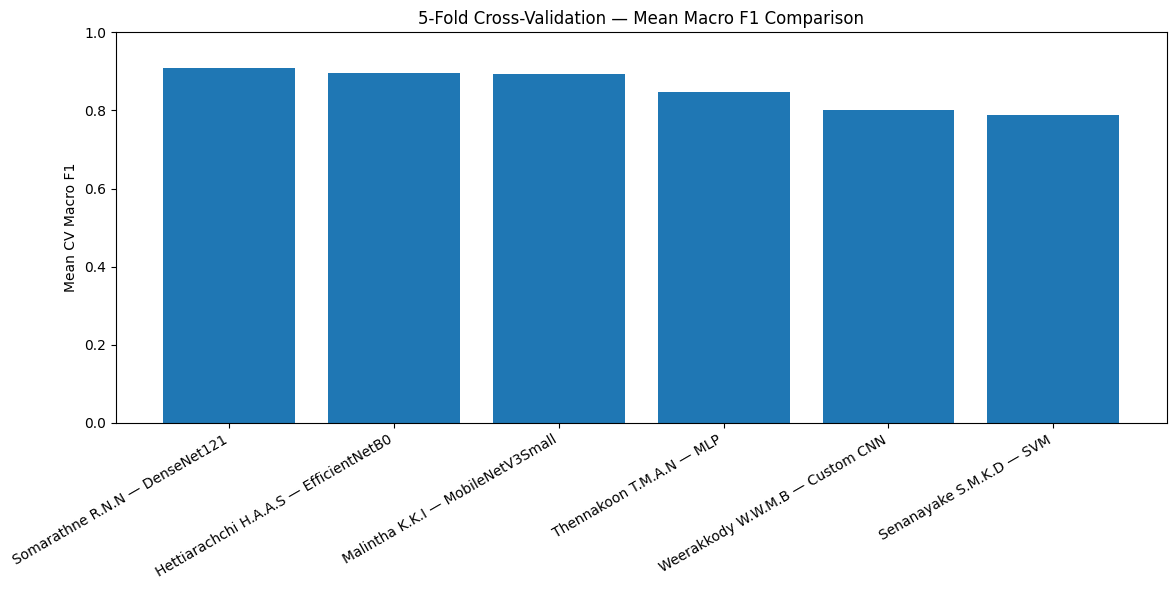

In [7]:
from google.colab import files
import io

print("Upload the SIX *_5fold_cv_summary.csv files now.")
cv_uploaded = files.upload()

cv_frames = []
for filename, content in cv_uploaded.items():
    if filename.lower().endswith("_5fold_cv_summary.csv"):
        df = pd.read_csv(io.BytesIO(content))
        if len(df) == 0:
            continue
        df["Source File"] = filename
        cv_frames.append(df)

if len(cv_frames) != 6:
    raise ValueError(
        f"Expected exactly 6 CV summary CSV files, found {len(cv_frames)}."
    )

combined_cv = pd.concat(cv_frames, ignore_index=True)

required = [
    "Owner", "IT Number", "Model", "Selected Variant",
    "Selected Variant Name", "Fold 1 F1", "Fold 2 F1",
    "Fold 3 F1", "Fold 4 F1", "Fold 5 F1",
    "Mean CV F1", "Std CV F1"
]

missing = [c for c in required if c not in combined_cv.columns]
if missing:
    raise ValueError("Missing required CV columns: " + ", ".join(missing))

for col in [
    "Fold 1 F1", "Fold 2 F1", "Fold 3 F1",
    "Fold 4 F1", "Fold 5 F1", "Mean CV F1", "Std CV F1"
]:
    combined_cv[col] = pd.to_numeric(combined_cv[col], errors="coerce")

combined_cv["Owner + Model"] = (
    combined_cv["Owner"].astype(str)
    + " — "
    + combined_cv["Model"].astype(str)
)

cv_ranking = (
    combined_cv
    .sort_values("Mean CV F1", ascending=False)
    .reset_index(drop=True)
)
cv_ranking.insert(0, "CV Rank", np.arange(1, len(cv_ranking) + 1))

print("FINAL 5-FOLD CROSS-VALIDATION COMPARISON")
display(
    cv_ranking[[
        "CV Rank", "Owner", "IT Number", "Model",
        "Selected Variant", "Selected Variant Name",
        "Fold 1 F1", "Fold 2 F1", "Fold 3 F1",
        "Fold 4 F1", "Fold 5 F1", "Mean CV F1", "Std CV F1"
    ]].round(4)
)

plt.figure(figsize=(12, 6))
plt.bar(cv_ranking["Owner + Model"], cv_ranking["Mean CV F1"])
plt.title("5-Fold Cross-Validation — Mean Macro F1 Comparison")
plt.ylabel("Mean CV Macro F1")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 8. Identify the Best Model

The official project selection rule uses **Validation Macro F1**. The 5-fold Mean Macro F1 is displayed as additional evidence of stability. Test metrics are not used to tune or override the selection rule.


In [8]:
best_validation_row = ranking.iloc[0]
best_cv_row = cv_ranking.iloc[0]

print("BEST MODEL BY THE PREDEFINED SELECTION RULE")
print("Owner:", best_validation_row["Student"])
print("IT Number:", best_validation_row["IT Number"])
print("Model:", best_validation_row["Model"])
print("Selected Variant:", best_validation_row["Selected Variant"])
print("Selected Variant Name:", best_validation_row["Selected Variant Name"])
print("Validation Macro F1:", round(float(best_validation_row["Validation F1"]), 4))
print("Official Test Macro F1:", round(float(best_validation_row["Test F1"]), 4))

print("\nHIGHEST MEAN 5-FOLD CV MACRO F1")
print("Owner:", best_cv_row["Owner"])
print("IT Number:", best_cv_row["IT Number"])
print("Model:", best_cv_row["Model"])
print("Mean CV Macro F1:", round(float(best_cv_row["Mean CV F1"]), 4))
print("CV Std Dev:", round(float(best_cv_row["Std CV F1"]), 4))

if (
    str(best_validation_row["Student"]) == str(best_cv_row["Owner"])
    and str(best_validation_row["Model"]) == str(best_cv_row["Model"])
):
    print("\nThe validation-selected model is also the strongest by mean 5-fold CV Macro F1.")
else:
    print("\nThe hold-out validation winner and CV winner differ. Keep the predefined Validation Macro F1 selection rule and discuss the CV result as generalization evidence.")


BEST MODEL BY THE PREDEFINED SELECTION RULE
Owner: Malintha K.K.I
IT Number: IT25102346
Model: MobileNetV3Small
Selected Variant: B
Selected Variant Name: Deep Regularized Fine-Tuning
Validation Macro F1: 0.9035
Official Test Macro F1: 0.6779

HIGHEST MEAN 5-FOLD CV MACRO F1
Owner: Somarathne R.N.N
IT Number: IT25100295
Model: DenseNet121
Mean CV Macro F1: 0.9092
CV Std Dev: 0.0198

The hold-out validation winner and CV winner differ. Keep the predefined Validation Macro F1 selection rule and discuss the CV result as generalization evidence.


## 9. Save Final Comparison Files


In [9]:
from pathlib import Path

OUT = Path("/content/final_comparison")
OUT.mkdir(parents=True, exist_ok=True)

FINAL_RESULT_CSV = OUT / "FINAL_6_OWNER_MODEL_COMPARISON.csv"
FINAL_CV_CSV = OUT / "FINAL_6_OWNER_5FOLD_CROSS_VALIDATION.csv"

ranking.to_csv(FINAL_RESULT_CSV, index=False)
cv_ranking.to_csv(FINAL_CV_CSV, index=False)

print("Saved:", FINAL_RESULT_CSV)
print("Saved:", FINAL_CV_CSV)


Saved: /content/final_comparison/FINAL_6_OWNER_MODEL_COMPARISON.csv
Saved: /content/final_comparison/FINAL_6_OWNER_5FOLD_CROSS_VALIDATION.csv


## 10. Download Final Comparison CSV Files


In [10]:
from google.colab import files
files.download(str(FINAL_RESULT_CSV))
files.download(str(FINAL_CV_CSV))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>